## Objetivo y fundamento teórico

| | **Random Forest** | **XGBoost** |
|---|---|---|
| Familia | Bagging (árboles en **paralelo**) | Boosting (árboles **secuenciales**) |
| Idea | Promediar muchos árboles profundos y descorrelacionados | Cada árbol corrige los residuos (gradiente) del anterior |
| Aleatorización | Bootstrap de filas + subconjunto aleatorio de $d<D$ variables en cada división | `subsample` de filas y `colsample_bytree` de columnas |
| Reduce principalmente | **Varianza** | **Sesgo** (y varianza vía regularización) |
| Regularización | `max_depth`, `min_samples_leaf`, `max_features` | $L_1$ (`reg_alpha`), $L_2$ (`reg_lambda`), `gamma`, `learning_rate`, `max_depth` |
| Faltantes | Requiere imputación | Manejo **nativo** (aprende la dirección por defecto de los NaN) |

XGBoost minimiza un objetivo regularizado con una aproximación de Taylor de **segundo orden**:
$$\mathcal{L}^{(t)} = \sum_i \left[g_i f_t(x_i) + \tfrac{1}{2} h_i f_t^2(x_i)\right] + \gamma T + \tfrac{1}{2}\lambda \sum_j w_j^2$$

**Dataset principal:** *Pima Indians Diabetes* (problema clínico difícil). Se comparan ambos modelos con
configuración base y **optimizados con `RandomizedSearchCV`**, midiendo eficacia (Accuracy, F1, ROC-AUC,
Log-Loss) y **eficiencia computacional** (tiempo de entrenamiento e inferencia). Se verifica además en *breast_cancer*.

In [1]:
# Librerías y configuración global de reproducibilidad
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
REPO_RAW = "https://raw.githubusercontent.com/Edwardmamani/ML-UNAP-Tarea-Ejecucion-03/main"


def load_csv(name):
    """Carga un CSV desde data/ (local) o desde el repositorio GitHub (Colab)."""
    local = os.path.join("data", name)
    return pd.read_csv(local if os.path.exists(local) else f"{REPO_RAW}/data/{name}")


def savefig(name):
    """Guarda la figura actual en figures/ (se reutiliza en el informe .docx)."""
    plt.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight")


def bootstrap_ci(y_true, y_score, metric, n_boot=1000, seed=RANDOM_STATE):
    """Intervalo de confianza bootstrap al 95% de una métrica sobre el conjunto de prueba."""
    rng = np.random.default_rng(seed)
    y_true, y_score = np.asarray(y_true), np.asarray(y_score)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2 and metric.__name__ == "roc_auc_score":
            continue
        vals.append(metric(y_true[idx], y_score[idx]))
    return np.percentile(vals, [2.5, 97.5])


def save_results(obj, name):
    """Guarda los resultados en results/<name>.json (insumo del informe)."""
    with open(f"results/{name}.json", "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False,
                  default=lambda o: o.item() if hasattr(o, "item") else str(o))


def plot_roc(ax, model, X_eval, y_eval, name, color=None, lw=1.8):
    """Dibuja la curva ROC de un modelo (compatible con cualquier versión de scikit-learn)."""
    from sklearn.metrics import roc_curve, roc_auc_score
    score = model.predict_proba(X_eval)[:, 1]
    fpr, tpr, _ = roc_curve(y_eval, score)
    ax.plot(fpr, tpr, color=color, lw=lw, label=f"{name} (AUC = {roc_auc_score(y_eval, score):.3f})")
    ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")
    ax.legend(loc="lower right", fontsize=8)


print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

try:
    import xgboost
except ImportError:                       # Colab ya incluye xgboost; por si acaso:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
    import xgboost
from xgboost import XGBClassifier
print("xgboost", xgboost.__version__)

scikit-learn 1.9.1 | pandas 3.1.0 | numpy 2.4.6


xgboost 3.2.0


## 1. Datos (mismo tratamiento de faltantes que el Ítem 3) y partición 80/20

In [2]:
ZERO_AS_NAN = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df = load_csv("diabetes.csv")
print("Dimensiones:", df.shape, "| duplicados:", int(df.duplicated().sum()))
print("Ceros fisiológicamente imposibles por columna:")
print((df[ZERO_AS_NAN] == 0).sum())
df[ZERO_AS_NAN] = df[ZERO_AS_NAN].replace(0, np.nan)      # un 0 en glucosa/IMC/presión = dato faltante
X, y = df.drop(columns="Outcome"), df["Outcome"]
print("\nDistribución de clases (1 = diabetes):", y.value_counts().to_dict(),
      f"| prevalencia = {y.mean():.3f}")

from sklearn.model_selection import train_test_split, StratifiedKFold
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Dimensiones: (768, 9) | duplicados: 0
Ceros fisiológicamente imposibles por columna:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Distribución de clases (1 = diabetes): {0: 500, 1: 268} | prevalencia = 0.349
Train: (614, 8) | Test: (154, 8)


Los ceros imposibles se convierten en `NaN`. **Random Forest** recibe una imputación por mediana (ajustada en
train) con indicadores de faltante; **XGBoost** recibe los `NaN` directamente porque los maneja de forma nativa.

## 2. Configuraciones base y búsqueda aleatoria de hiperparámetros

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import RandomizedSearchCV

def rf_pipe(**kw):
    return Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                     ("clf", RandomForestClassifier(random_state=RANDOM_STATE, **kw))])

rf_base = rf_pipe(n_estimators=300, max_features="sqrt", n_jobs=-1)
xgb_base = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                         colsample_bytree=0.8, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rf_space = {"clf__n_estimators": [200, 300, 500], "clf__max_depth": [None, 4, 6, 8, 12],
            "clf__min_samples_leaf": [1, 2, 4, 8], "clf__max_features": ["sqrt", "log2", 0.5]}
xgb_space = {"n_estimators": [100, 200, 300, 500], "learning_rate": [0.01, 0.03, 0.05, 0.1],
             "max_depth": [2, 3, 4, 5, 6], "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.6, 0.8, 1.0],
             "min_child_weight": [1, 3, 5], "reg_lambda": [0.5, 1, 2, 5], "gamma": [0, 0.1, 0.5]}

t0 = time.perf_counter()
rf_search = RandomizedSearchCV(rf_pipe(n_jobs=1), rf_space, n_iter=40, cv=cv5, scoring="roc_auc",
                               n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
rf_search_t = time.perf_counter() - t0
t0 = time.perf_counter()
xgb_search = RandomizedSearchCV(XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1),
                                xgb_space, n_iter=40, cv=cv5, scoring="roc_auc", n_jobs=-1,
                                random_state=RANDOM_STATE).fit(X_train, y_train)
xgb_search_t = time.perf_counter() - t0
rf_best = {k.replace("clf__", ""): v for k, v in rf_search.best_params_.items()}
xgb_best = xgb_search.best_params_
print(f"RF  mejores params: {rf_best} | AUC CV5 = {rf_search.best_score_:.4f} | búsqueda {rf_search_t:.1f}s")
print(f"XGB mejores params: {xgb_best} | AUC CV5 = {xgb_search.best_score_:.4f} | búsqueda {xgb_search_t:.1f}s")

models = {
    "Baseline (clase mayoritaria)": DummyClassifier(strategy="most_frequent"),
    "Random Forest (base)": rf_base,
    "Random Forest (optimizado)": rf_pipe(n_jobs=-1, **rf_best),
    "XGBoost (base)": xgb_base,
    "XGBoost (optimizado)": XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1,
                                          **xgb_best),
}

RF  mejores params: {'n_estimators': 500, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 4} | AUC CV5 = 0.8377 | búsqueda 85.9s
XGB mejores params: {'subsample': 0.8, 'reg_lambda': 5, 'n_estimators': 100, 'min_child_weight': 5, 'max_depth': 2, 'learning_rate': 0.05, 'gamma': 0.1, 'colsample_bytree': 0.6} | AUC CV5 = 0.8400 | búsqueda 14.2s


_(análisis pendiente)_

## 3. Evaluación: eficacia predictiva y eficiencia computacional

In [4]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             log_loss, balanced_accuracy_score)

rows, cv_auc = [], {}
for name, model in models.items():
    cvres = cross_validate(model, X_train, y_train, cv=cv, scoring=["accuracy", "f1", "roc_auc"], n_jobs=1)
    fit_times = []
    for _ in range(3):
        t0 = time.perf_counter(); model.fit(X_train, y_train); fit_times.append(time.perf_counter() - t0)
    t0 = time.perf_counter()
    for _ in range(20):
        y_proba = model.predict_proba(X_test)[:, 1]
    inf_ms = (time.perf_counter() - t0) / 20 / len(X_test) * 1000
    y_pred = model.predict(X_test)
    cv_auc[name] = cvres["test_roc_auc"]
    rows.append({
        "Modelo": name,
        "Acc. CV (media)": cvres["test_accuracy"].mean(), "Acc. CV (std)": cvres["test_accuracy"].std(),
        "F1 CV": cvres["test_f1"].mean(), "ROC-AUC CV": cvres["test_roc_auc"].mean(),
        "Acc. train": accuracy_score(y_train, model.predict(X_train)),
        "Acc. test": accuracy_score(y_test, y_pred),
        "Acc. balanceada test": balanced_accuracy_score(y_test, y_pred),
        "Precisión test": precision_score(y_test, y_pred, zero_division=0),
        "Recall test": recall_score(y_test, y_pred), "F1 test": f1_score(y_test, y_pred),
        "ROC-AUC test": roc_auc_score(y_test, y_proba), "Log-Loss test": log_loss(y_test, y_proba),
        "Tiempo fit (s)": float(np.median(fit_times)), "Inferencia (ms/muestra)": inf_ms,
    })
results = pd.DataFrame(rows).set_index("Modelo")
results.round(4)

,Acc. CV (media),Acc. CV (std),F1 CV,ROC-AUC CV,Acc. train,Acc. test,Acc. balanceada test,Precisión test,Recall test,F1 test,ROC-AUC test,Log-Loss test,Tiempo fit (s),Inferencia (ms/muestra)
Modelo,,,,,,,,,,,,,,
Baseline (clase mayoritaria),0.6515,0.0052,0.0000,0.5000,0.6515,0.6494,0.5000,0.0000,0.0000,0.0000,0.5000,12.6387,0.0009,0.0003
Random Forest (base),0.7557,0.0486,0.6228,0.8187,1.0000,0.7338,0.6928,0.6383,0.5556,0.5941,0.8079,0.4996,1.0779,0.6799
Random Forest (optimizado),0.7672,0.0317,0.5993,0.8354,0.8160,0.7273,0.6665,0.6579,0.4630,0.5435,0.8035,0.5126,1.5354,0.9497
XGBoost (base),0.7492,0.0536,0.6164,0.8016,0.9821,0.7468,0.7198,0.6415,0.6296,0.6355,0.8211,0.5459,3.9988,0.0847
XGBoost (optimizado),0.7591,0.0451,0.6057,0.8320,0.8062,0.7403,0.6893,0.6667,0.5185,0.5833,0.8209,0.4914,0.1725,0.0414


_(análisis pendiente)_

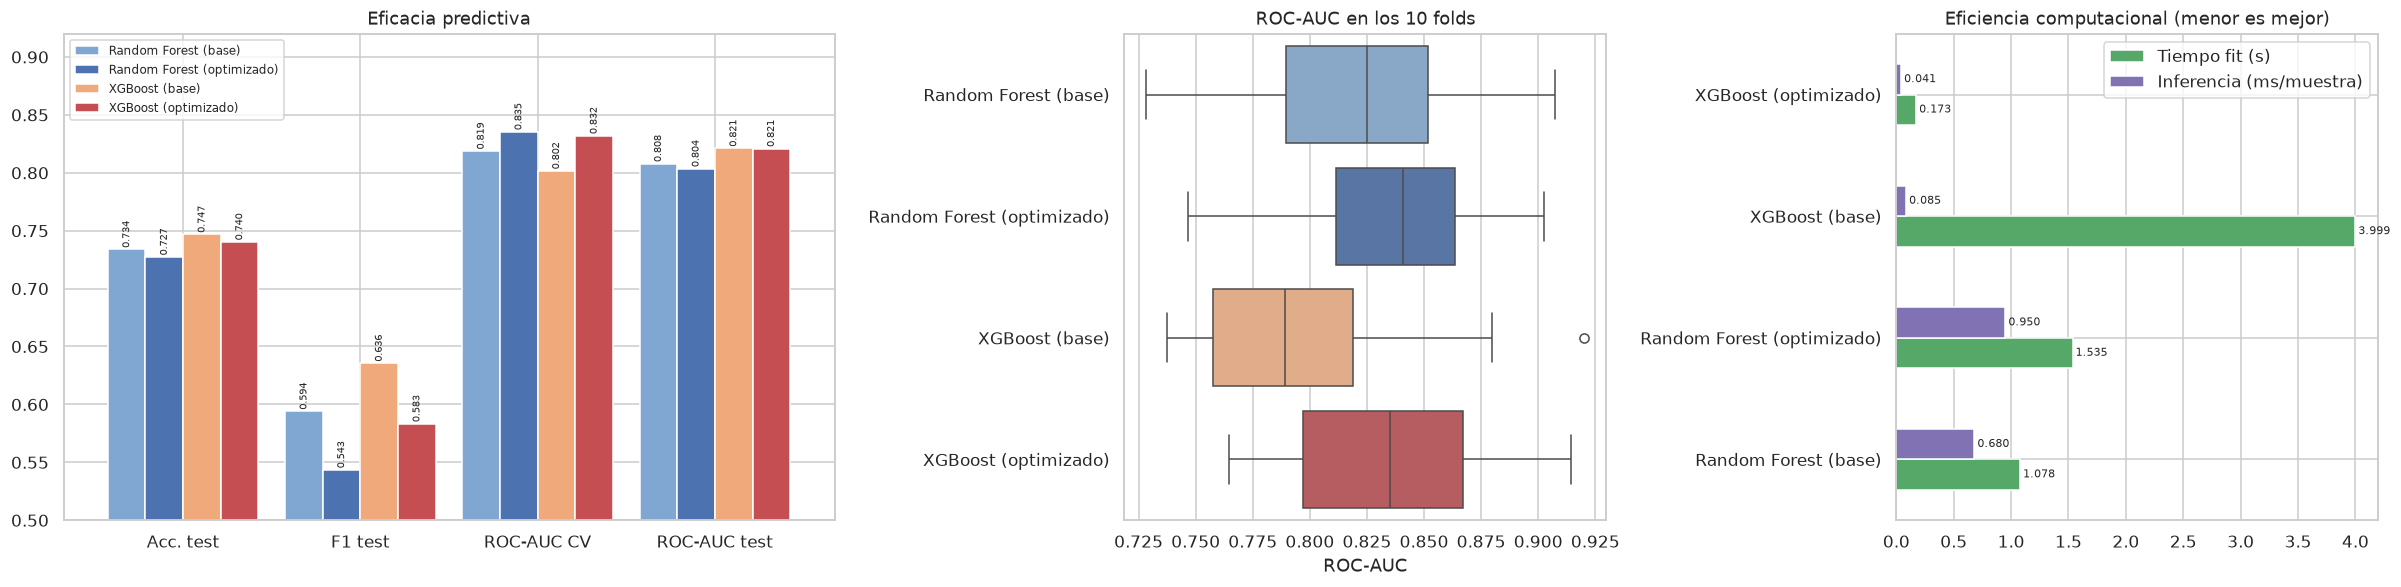

In [5]:
main = [m for m in models if "Baseline" not in m]
colors = ["#7FA7D1", "#4C72B0", "#F0A97A", "#C44E52"]
fig, axes = plt.subplots(1, 3, figsize=(22, 5.5), gridspec_kw={"width_ratios": [1.6, 1, 1]})
results.loc[main, ["Acc. test", "F1 test", "ROC-AUC CV", "ROC-AUC test"]].T.plot(
    kind="bar", ax=axes[0], color=colors, width=0.85)
axes[0].set_ylim(0.5, 0.92); axes[0].tick_params(axis="x", rotation=0)
axes[0].set_title("Eficacia predictiva"); axes[0].legend(fontsize=8, loc="upper left")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.3f", fontsize=6.5, rotation=90, padding=1)
cv_df = pd.DataFrame({k: cv_auc[k] for k in main}).melt(var_name="Modelo", value_name="ROC-AUC")
sns.boxplot(data=cv_df, y="Modelo", x="ROC-AUC", hue="Modelo", palette=colors, legend=False, ax=axes[1])
axes[1].set_title("ROC-AUC en los 10 folds"); axes[1].set_ylabel("")
eff = results.loc[main, ["Tiempo fit (s)", "Inferencia (ms/muestra)"]]
eff.plot(kind="barh", ax=axes[2], color=["#55A868", "#8172B3"])
axes[2].set_title("Eficiencia computacional (menor es mejor)"); axes[2].set_ylabel("")
for c in axes[2].containers:
    axes[2].bar_label(c, fmt="%.3f", fontsize=7, padding=2)
plt.tight_layout(); savefig("item5_comparacion"); plt.show()

_(análisis pendiente)_

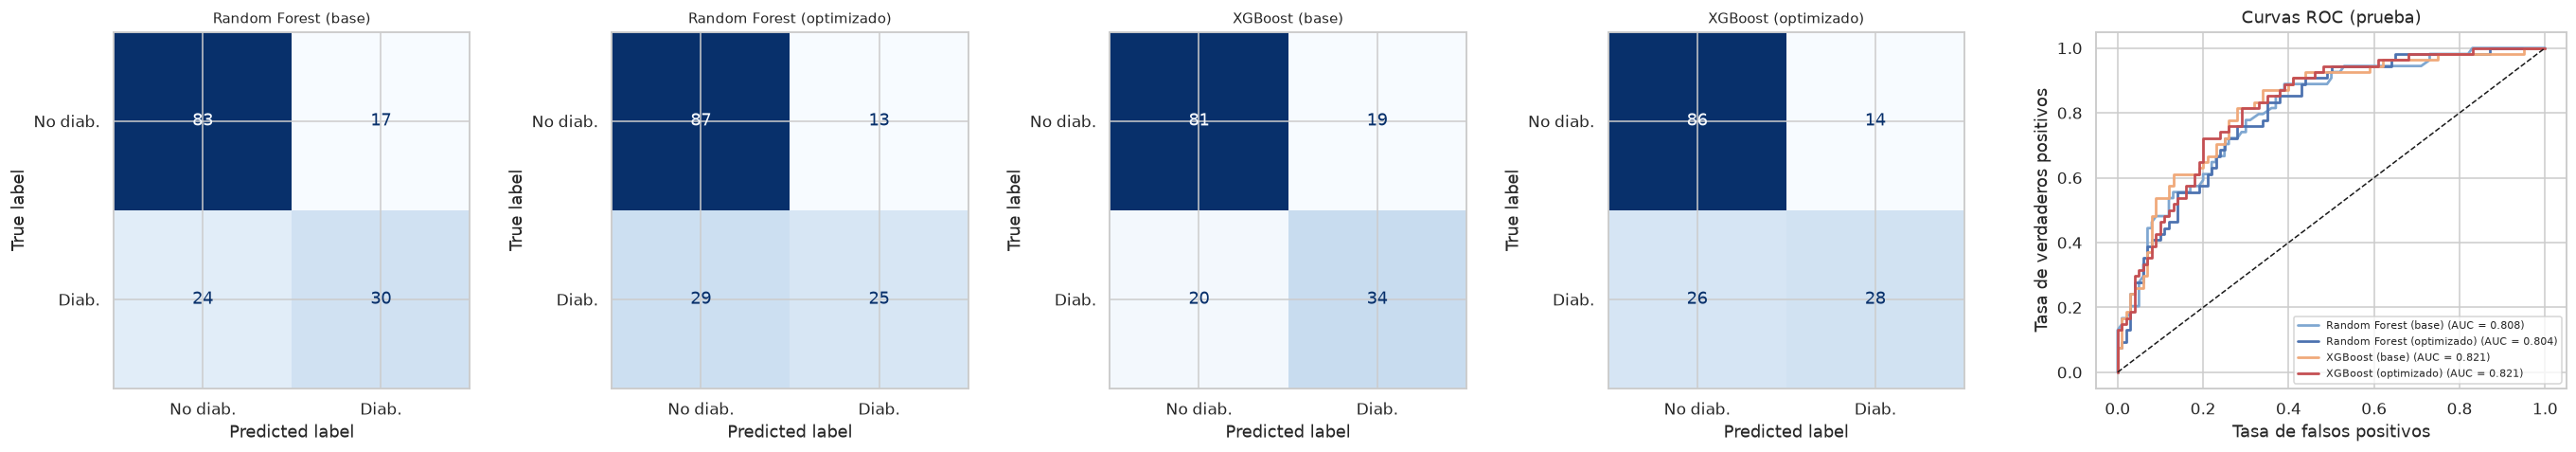

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 5, figsize=(25, 4.5), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.25]})
for ax, name in zip(axes[:4], main):
    ConfusionMatrixDisplay.from_predictions(y_test, models[name].predict(X_test),
                                            display_labels=["No diab.", "Diab."], cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(name, fontsize=10)
for name, col in zip(main, colors):
    plot_roc(axes[4], models[name], X_test, y_test, name, color=col)
axes[4].plot([0, 1], [0, 1], "k--", lw=1); axes[4].set_title("Curvas ROC (prueba)"); axes[4].legend(fontsize=7)
plt.tight_layout(); savefig("item5_confusion_roc"); plt.show()

_(análisis pendiente)_

## 4. Curvas de aprendizaje: OOB de Random Forest y Log-Loss de XGBoost por iteración

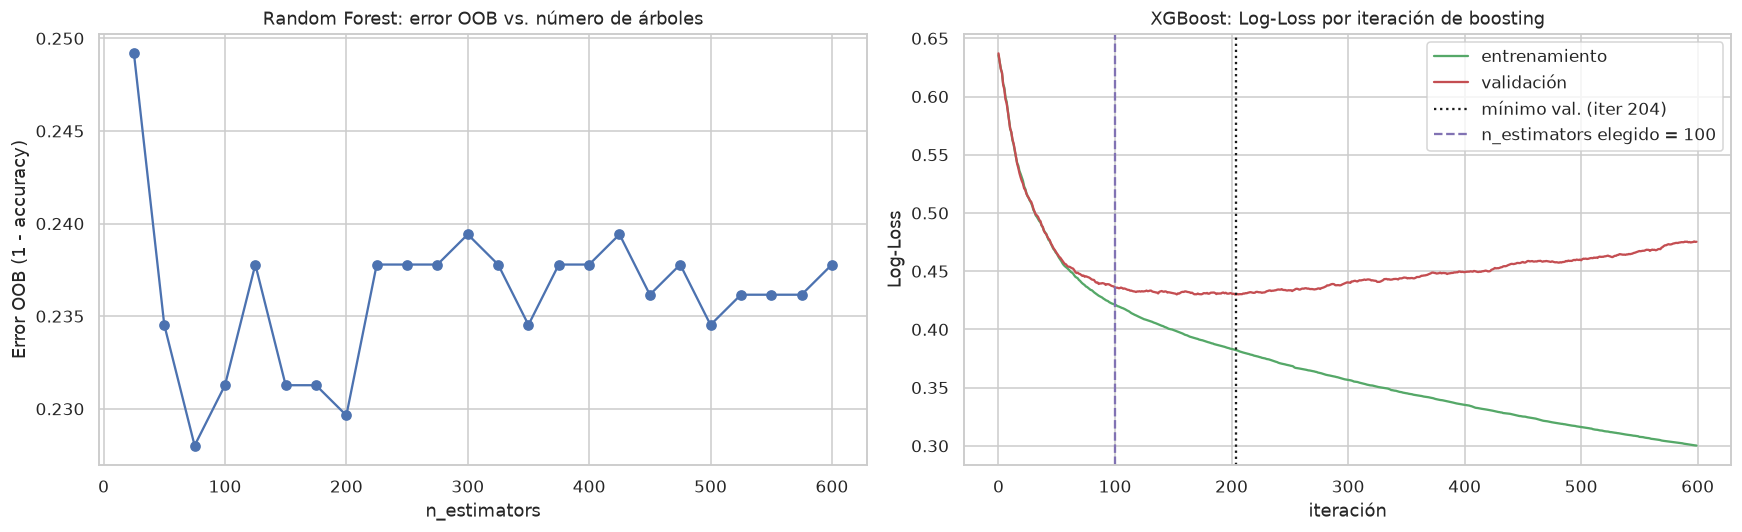

RF error OOB: inicial 0.2492 -> final 0.2378
XGB log-loss val mínimo 0.4299 en iter 204; final (600) 0.4752


In [7]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train,
                                              random_state=RANDOM_STATE)
# XGBoost: pérdida en entrenamiento y validación (separada de train; el test no se usa)
xgb_curve = XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1,
                          **{**xgb_best, "n_estimators": 600})
xgb_curve.fit(X_fit, y_fit, eval_set=[(X_fit, y_fit), (X_val, y_val)], verbose=False)
ev = xgb_curve.evals_result()
# Random Forest: error OOB al crecer el bosque
imp_rf = SimpleImputer(strategy="median", add_indicator=True).fit(X_train)
Xi = imp_rf.transform(X_train)
rf_oob = RandomForestClassifier(oob_score=True, warm_start=True, random_state=RANDOM_STATE, n_jobs=-1,
                                **{k: v for k, v in rf_best.items() if k != "n_estimators"})
oob_err, n_grid = [], list(range(25, 601, 25))
for n_ in n_grid:
    rf_oob.set_params(n_estimators=n_).fit(Xi, y_train); oob_err.append(1 - rf_oob.oob_score_)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(n_grid, oob_err, "-o", color="#4C72B0")
axes[0].set_title("Random Forest: error OOB vs. número de árboles")
axes[0].set_xlabel("n_estimators"); axes[0].set_ylabel("Error OOB (1 - accuracy)")
axes[1].plot(ev["validation_0"]["logloss"], color="#55A868", label="entrenamiento")
axes[1].plot(ev["validation_1"]["logloss"], color="#C44E52", label="validación")
best_it = int(np.argmin(ev["validation_1"]["logloss"]))
axes[1].axvline(best_it, color="k", ls=":", label=f"mínimo val. (iter {best_it})")
axes[1].axvline(xgb_best["n_estimators"], color="#8172B3", ls="--",
                label=f"n_estimators elegido = {xgb_best['n_estimators']}")
axes[1].set_title("XGBoost: Log-Loss por iteración de boosting"); axes[1].set_xlabel("iteración")
axes[1].set_ylabel("Log-Loss"); axes[1].legend()
plt.tight_layout(); savefig("item5_curvas"); plt.show()
print(f"RF error OOB: inicial {oob_err[0]:.4f} -> final {oob_err[-1]:.4f}")
print(f"XGB log-loss val mínimo {min(ev['validation_1']['logloss']):.4f} en iter {best_it}; "
      f"final (600) {ev['validation_1']['logloss'][-1]:.4f}")

_(análisis pendiente)_

## 5. Importancia de variables: MDI (RF), Gain (XGBoost) y permutación (ambos)

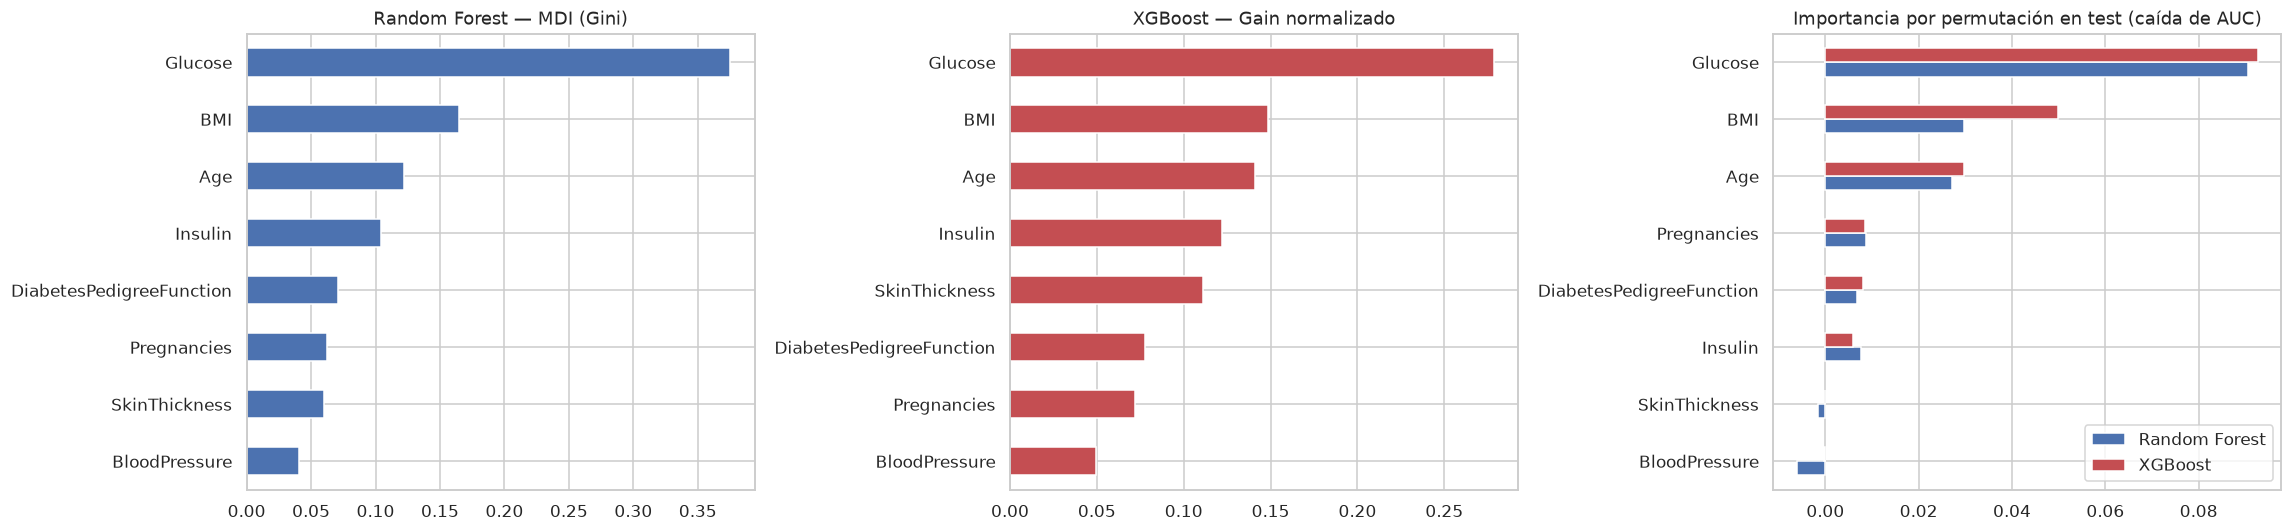

,MDI RF,Gain XGB,Perm. Random Forest,Perm. XGBoost
Glucose,0.3753,0.2785,0.0906,0.0928
BMI,0.1644,0.1485,0.0298,0.0498
Age,0.1221,0.1411,0.0271,0.0297
Insulin,0.1040,0.1218,0.0077,0.0059
DiabetesPedigreeFunction,0.0709,0.0775,0.0069,0.0080
Pregnancies,0.0621,0.0718,0.0088,0.0084
SkinThickness,0.0604,0.1111,-0.0016,0.0000
BloodPressure,0.0409,0.0496,-0.0062,-0.0002


In [8]:
from sklearn.inspection import permutation_importance

rf_opt, xgb_opt = models["Random Forest (optimizado)"], models["XGBoost (optimizado)"]
rf_names = list(X.columns) + [f"falta_{X.columns[i]}" for i in rf_opt.named_steps["imp"].indicator_.features_]
mdi = pd.Series(rf_opt.named_steps["clf"].feature_importances_, index=rf_names)
mdi = mdi.groupby(lambda c: c.replace("falta_", "")).sum()   # agrega el indicador a su variable
gain = pd.Series(xgb_opt.get_booster().get_score(importance_type="gain")).reindex(X.columns).fillna(0)
gain = gain / gain.sum()
perm = pd.DataFrame({
    "Random Forest": permutation_importance(rf_opt, X_test, y_test, scoring="roc_auc", n_repeats=30,
                                            random_state=RANDOM_STATE).importances_mean,
    "XGBoost": permutation_importance(xgb_opt, X_test, y_test, scoring="roc_auc", n_repeats=30,
                                      random_state=RANDOM_STATE).importances_mean}, index=X.columns)

fig, axes = plt.subplots(1, 3, figsize=(21, 5))
mdi.sort_values().plot(kind="barh", ax=axes[0], color="#4C72B0"); axes[0].set_title("Random Forest — MDI (Gini)")
gain.sort_values().plot(kind="barh", ax=axes[1], color="#C44E52"); axes[1].set_title("XGBoost — Gain normalizado")
perm.sort_values("XGBoost").plot(kind="barh", ax=axes[2], color=["#4C72B0", "#C44E52"])
axes[2].set_title("Importancia por permutación en test (caída de AUC)")
plt.tight_layout(); savefig("item5_importancia"); plt.show()
pd.DataFrame({"MDI RF": mdi, "Gain XGB": gain}).join(perm.add_prefix("Perm. ")).sort_values("MDI RF",
                                                                                            ascending=False).round(4)

_(análisis pendiente)_

## 6. Significancia estadística (CV repetida 10×3 + Wilcoxon) e IC bootstrap de la diferencia de AUC

In [9]:
from scipy.stats import wilcoxon
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

rcv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=RANDOM_STATE)
rep = {n: cross_val_score(models[n], X_train, y_train, cv=rcv, scoring="roc_auc", n_jobs=1) for n in main}
pairs = [("Random Forest (optimizado)", "XGBoost (optimizado)"), ("Random Forest (base)", "XGBoost (base)"),
         ("XGBoost (optimizado)", "XGBoost (base)"), ("Random Forest (optimizado)", "Random Forest (base)")]
stats_rows = []
for a, b in pairs:
    p = wilcoxon(rep[a], rep[b], zero_method="zsplit").pvalue
    stats_rows.append({"Comparación": f"{a} vs {b}", "AUC A": rep[a].mean(), "AUC B": rep[b].mean(),
                       "Diferencia A-B": (rep[a] - rep[b]).mean(), "p-valor Wilcoxon": p,
                       "Significativo (α=0.05)": "Sí" if p < 0.05 else "No"})
stats_df = pd.DataFrame(stats_rows)

rng = np.random.default_rng(RANDOM_STATE)
p_rf, p_xgb = rf_opt.predict_proba(X_test)[:, 1], xgb_opt.predict_proba(X_test)[:, 1]
yt = y_test.values; diffs = []
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[idx])) == 2:
        diffs.append(roc_auc_score(yt[idx], p_rf[idx]) - roc_auc_score(yt[idx], p_xgb[idx]))
auc_diff_ci = np.percentile(diffs, [2.5, 97.5])
ci_df = pd.DataFrame({n: bootstrap_ci(y_test, models[n].predict_proba(X_test)[:, 1], roc_auc_score)
                      for n in main}, index=["AUC IC95% inf", "AUC IC95% sup"]).T
display(stats_df.round(4)); display(ci_df.round(4))
print(f"Diferencia AUC test (RF opt - XGB opt) = {np.mean(diffs):.4f}, IC95% = [{auc_diff_ci[0]:.4f}, {auc_diff_ci[1]:.4f}]")

,Comparación,AUC A,AUC B,Diferencia A-B,p-valor Wilcoxon,Significativo (α=0.05)
0,Random Forest (optimizado) vs XGBoost (optimiz...,0.8349,0.8342,0.0007,0.7188,No
1,Random Forest (base) vs XGBoost (base),0.8227,0.8069,0.0159,0.0002,Sí
2,XGBoost (optimizado) vs XGBoost (base),0.8342,0.8069,0.0273,0.0000,Sí
3,Random Forest (optimizado) vs Random Forest (b...,0.8349,0.8227,0.0122,0.0004,Sí


,AUC IC95% inf,AUC IC95% sup
Random Forest (base),0.7308,0.8742
Random Forest (optimizado),0.7278,0.8707
XGBoost (base),0.7442,0.8860
XGBoost (optimizado),0.7497,0.8846


Diferencia AUC test (RF opt - XGB opt) = -0.0176, IC95% = [-0.0335, -0.0029]


_(análisis pendiente)_

## 7. Verificación en un segundo dataset (breast_cancer)

In [10]:
from sklearn.datasets import load_breast_cancer

Xb, yb = load_breast_cancer(return_X_y=True, as_frame=True)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.2, stratify=yb, random_state=RANDOM_STATE)
bc_models = {"Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
             "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                                      colsample_bytree=0.8, eval_metric="logloss",
                                      random_state=RANDOM_STATE, n_jobs=-1)}
bc_rows = []
for n_, m in bc_models.items():
    s = cross_validate(m, Xb_tr, yb_tr, cv=cv, scoring=["accuracy", "roc_auc"])
    t0 = time.perf_counter(); m.fit(Xb_tr, yb_tr); ft = time.perf_counter() - t0
    bc_rows.append({"Modelo": n_, "Acc. CV": s["test_accuracy"].mean(), "AUC CV": s["test_roc_auc"].mean(),
                    "Acc. test": m.score(Xb_te, yb_te),
                    "AUC test": roc_auc_score(yb_te, m.predict_proba(Xb_te)[:, 1]), "Tiempo fit (s)": ft})
bc_df = pd.DataFrame(bc_rows).set_index("Modelo")
bc_df.round(4)

,Acc. CV,AUC CV,Acc. test,AUC test,Tiempo fit (s)
Modelo,,,,,
Random Forest,0.9628,0.9891,0.9474,0.9937,0.4842
XGBoost,0.9714,0.9939,0.9561,0.9947,0.1360


_(análisis pendiente)_

In [11]:
save_results({
    "results": results.reset_index().to_dict(orient="records"),
    "rf_best": rf_best, "xgb_best": xgb_best,
    "rf_search_auc": rf_search.best_score_, "xgb_search_auc": xgb_search.best_score_,
    "rf_search_time": rf_search_t, "xgb_search_time": xgb_search_t,
    "stats": stats_df.to_dict(orient="records"),
    "ci": ci_df.reset_index().rename(columns={"index": "Modelo"}).to_dict(orient="records"),
    "auc_diff_ci": list(auc_diff_ci), "auc_diff_mean": float(np.mean(diffs)),
    "oob": {"first": oob_err[0], "last": oob_err[-1]},
    "xgb_curve": {"best_iter": best_it, "min_val": min(ev["validation_1"]["logloss"]),
                  "final_val": ev["validation_1"]["logloss"][-1]},
    "breast_cancer": bc_df.reset_index().to_dict(orient="records"),
    "importance": pd.DataFrame({"MDI RF": mdi, "Gain XGB": gain}).join(perm.add_prefix("Perm. "))
                    .reset_index().rename(columns={"index": "Variable"}).to_dict(orient="records"),
}, "item5")
print("Resultados guardados en results/item5.json")

Resultados guardados en results/item5.json


## Conclusiones
_(pendiente)_